# Phishing Website Detection (Machine Learning)
This notebook builds a phishing URL classifier using engineered URL/HTML features and evaluates multiple models.

## Highlights
- Exploratory data analysis and feature selection
- Model comparison (LR, RF, SVM, XGBoost) and ensemble voting
- Robust evaluation: cross-validation, ROC/PR curves, threshold tuning
- Error analysis and permutation importance
- Gradio demo for interactive inference

## How to run
1. Ensure phishing.csv is in the same folder as this notebook.
2. Install dependencies: pip install -r requirements.txt
3. Run the notebook top to bottom.

## Notes
- Feature extraction makes live HTTP/HTTPS requests; results can vary over time.
- Random seed used where applicable: 42.

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
%matplotlib inline

In [ ]:
#from google.colab import drive
#drive.mount('https://drive.google.com/file/d/1BttU8i118m_bXmUP2wcTPsFdAPKMNu_3/view?usp=drive_link')

MessageError: Error: credential propagation was unsuccessful

: 

In [5]:
data = pd.read_csv('phishing.csv')
data.head()

,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
0,0,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
1,1,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
2,2,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
3,3,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1
4,4,-1,0,-1,1,-1,-1,1,1,-1,...,1,1,1,1,1,-1,1,-1,-1,1


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 11054 entries, 0 to 11053
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Index                11054 non-null  int64
 1   UsingIP              11054 non-null  int64
 2   LongURL              11054 non-null  int64
 3   ShortURL             11054 non-null  int64
 4   Symbol@              11054 non-null  int64
 5   Redirecting//        11054 non-null  int64
 6   PrefixSuffix-        11054 non-null  int64
 7   SubDomains           11054 non-null  int64
 8   HTTPS                11054 non-null  int64
 9   DomainRegLen         11054 non-null  int64
 10  Favicon              11054 non-null  int64
 11  NonStdPort           11054 non-null  int64
 12  HTTPSDomainURL       11054 non-null  int64
 13  RequestURL           11054 non-null  int64
 14  AnchorURL            11054 non-null  int64
 15  LinksInScriptTags    11054 non-null  int64
 16  ServerFormHandler    11054 non-nu

In [7]:
data.shape

(11054, 32)

In [8]:
data=data.drop('Index',axis=1)

In [9]:
data

,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,Favicon,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
0,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
1,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
2,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
3,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1
4,-1,0,-1,1,-1,-1,1,1,-1,1,...,1,1,1,1,1,-1,1,-1,-1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11049,1,-1,1,-1,1,1,1,1,-1,-1,...,-1,-1,1,1,-1,-1,1,1,1,1
11050,-1,1,1,-1,-1,-1,1,-1,-1,-1,...,-1,1,1,1,1,1,1,-1,1,-1
11051,1,-1,1,1,1,-1,1,-1,-1,1,...,1,1,1,1,1,-1,1,0,1,-1
11052,-1,-1,1,1,1,-1,-1,-1,1,-1,...,-1,1,1,1,1,-1,1,1,1,-1


In [10]:
data.describe()

,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,Favicon,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
count,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,...,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000
mean,0.313914,-0.633345,0.738737,0.700561,0.741632,-0.734938,0.064049,0.251040,-0.336711,0.628551,...,0.613353,0.816899,0.061335,0.377239,0.287407,-0.483626,0.721549,0.343948,0.719739,0.113986
std,0.949495,0.765973,0.674024,0.713625,0.670837,0.678165,0.817492,0.911856,0.941651,0.777804,...,0.789845,0.576807,0.998162,0.926158,0.827680,0.875314,0.692395,0.569936,0.694276,0.993527
min,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,-1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,...,1.000000,1.000000,-1.000000,-1.000000,0.000000,-1.000000,1.000000,0.000000,1.000000,-1.000000
50%,1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,0.000000,1.000000,-1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,0.000000,1.000000,1.000000
75%,1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [11]:
data.isnull().sum()

UsingIP                0
LongURL                0
ShortURL               0
Symbol@                0
Redirecting//          0
PrefixSuffix-          0
SubDomains             0
HTTPS                  0
DomainRegLen           0
Favicon                0
NonStdPort             0
HTTPSDomainURL         0
RequestURL             0
AnchorURL              0
LinksInScriptTags      0
ServerFormHandler      0
InfoEmail              0
AbnormalURL            0
WebsiteForwarding      0
StatusBarCust          0
DisableRightClick      0
UsingPopupWindow       0
IframeRedirection      0
AgeofDomain            0
DNSRecording           0
WebsiteTraffic         0
PageRank               0
GoogleIndex            0
LinksPointingToPage    0
StatsReport            0
class                  0
dtype: int64

In [12]:
data["LongURL"].value_counts()

LongURL
-1    8960
 1    1959
 0     135
Name: count, dtype: int64

In [13]:
data.duplicated().sum()

np.int64(5205)

In [14]:
data.columns

Index(['UsingIP', 'LongURL', 'ShortURL', 'Symbol@', 'Redirecting//',
       'PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'Favicon',
       'NonStdPort', 'HTTPSDomainURL', 'RequestURL', 'AnchorURL',
       'LinksInScriptTags', 'ServerFormHandler', 'InfoEmail', 'AbnormalURL',
       'WebsiteForwarding', 'StatusBarCust', 'DisableRightClick',
       'UsingPopupWindow', 'IframeRedirection', 'AgeofDomain', 'DNSRecording',
       'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'LinksPointingToPage',
       'StatsReport', 'class'],
      dtype='str')

In [15]:
data['class'].value_counts()

class
 1    6157
-1    4897
Name: count, dtype: int64

In [16]:
data["class"] = data["class"].replace(-1,0)
count = data['class'].value_counts()

In [17]:
data['class'].value_counts()

class
1    6157
0    4897
Name: count, dtype: int64

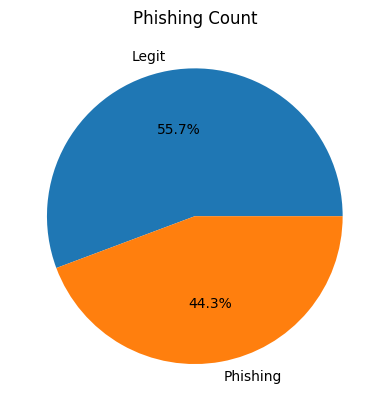

In [18]:
plt.pie(data['class'].value_counts(),labels=["Legit","Phishing"],autopct='%.1f%%')
plt.title("Phishing Count")
plt.show()

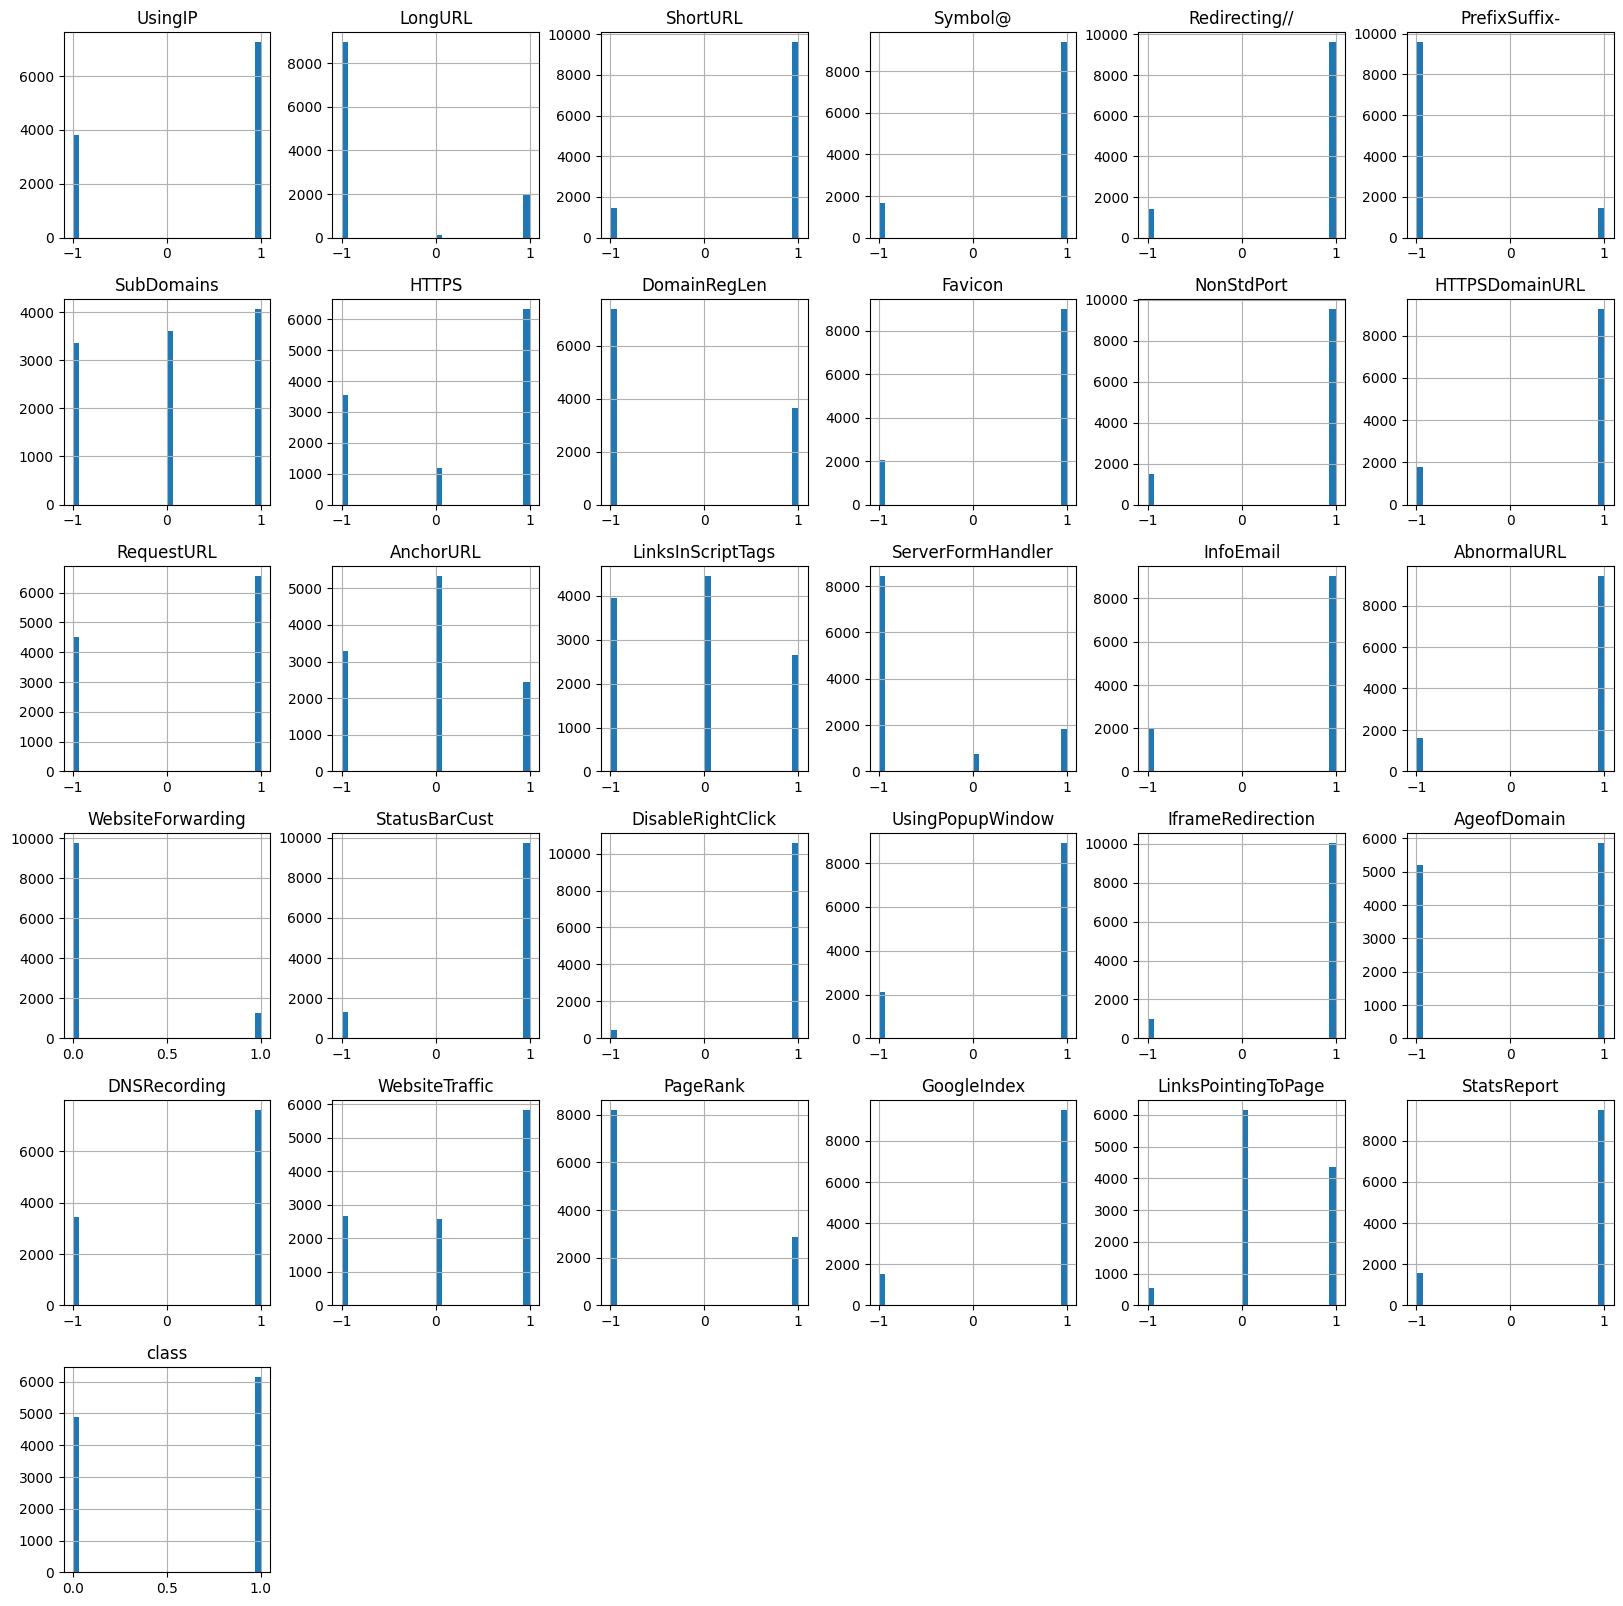

In [19]:
data.hist(figsize=(20, 20), bins=30)
plt.show()

<Axes: >

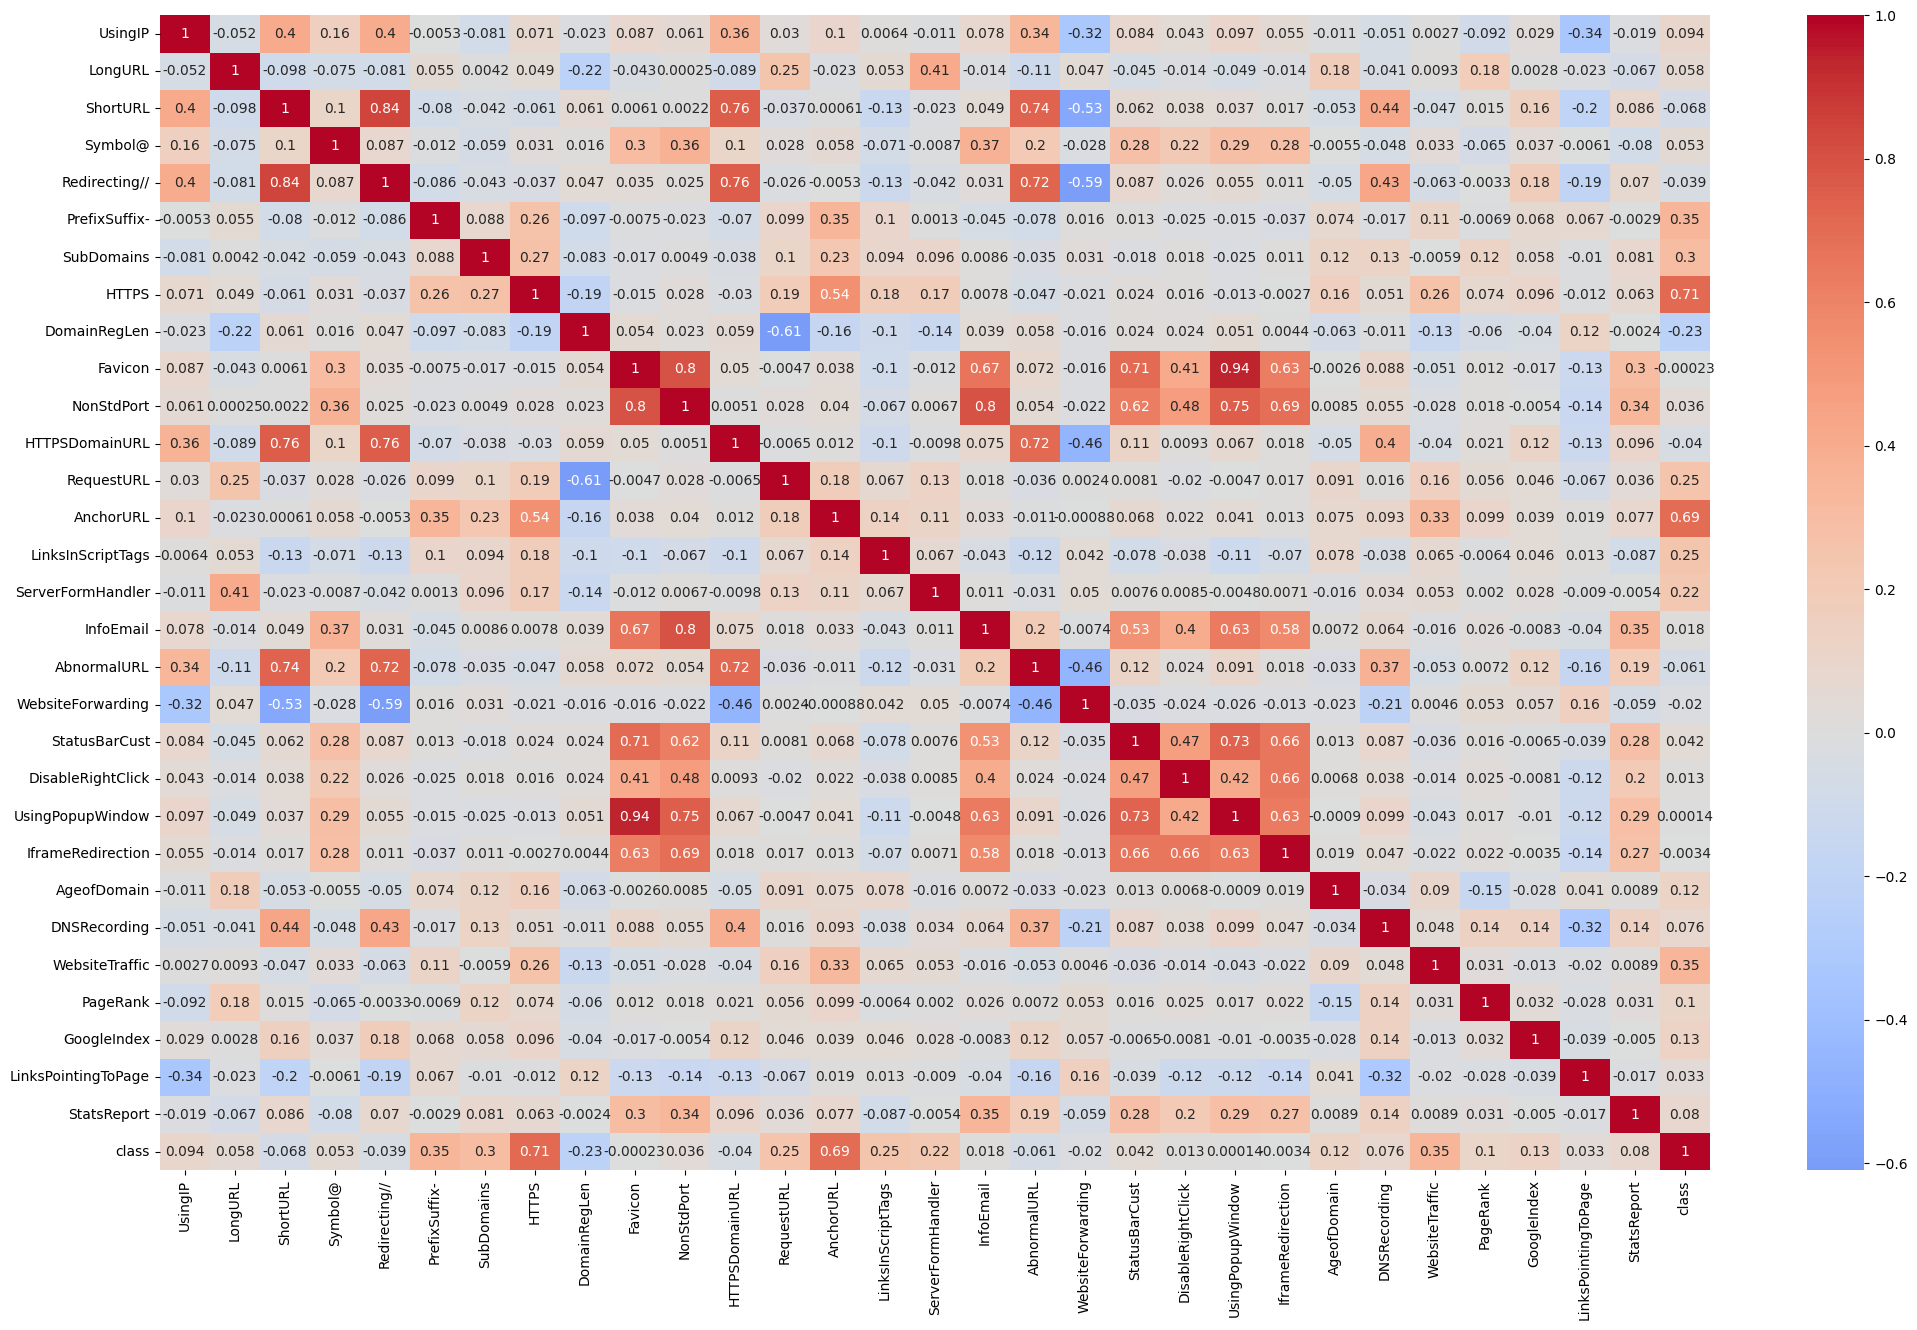

In [20]:
corr_matrix = data.corr()
plt.figure(figsize=(25, 15))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)

In [21]:
features = data.columns[0:-1]
target =  data.columns[-1]

X = data[features]
y = data[target]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [23]:
# Get all feature names
all_features = X.columns

# Initialize SelectPercentile
selector = SelectPercentile(percentile=60, score_func=f_classif)

# Fit the selector to the training data
selector.fit(X_train, y_train)

# Get the p-values
p_values = selector.pvalues_

# Adjust the length of p_values to match all_features
if len(p_values) != len(all_features):
    feature_pvalues = pd.Series(p_values, index=all_features[:len(p_values)])
else:
    feature_pvalues = pd.Series(p_values, index=all_features)

# Get the indices of the selected features
selected_features_idx = selector.get_support(indices=True)

# Get the names of the selected features
selected_features = all_features[selected_features_idx]
print("Selected Features:", selected_features)

# Print p-values of all features
print("\nP-Values of all features:\n", feature_pvalues)

Selected Features: Index(['UsingIP', 'LongURL', 'ShortURL', 'PrefixSuffix-', 'SubDomains',
       'HTTPS', 'DomainRegLen', 'RequestURL', 'AnchorURL', 'LinksInScriptTags',
       'ServerFormHandler', 'AbnormalURL', 'AgeofDomain', 'DNSRecording',
       'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'StatsReport'],
      dtype='str')

P-Values of all features:
 UsingIP                 3.511128e-18
LongURL                 1.121013e-06
ShortURL                5.080260e-10
Symbol@                 5.793158e-06
Redirecting//           2.041584e-04
PrefixSuffix-          8.646427e-221
SubDomains             3.568288e-157
HTTPS                   0.000000e+00
DomainRegLen            2.151858e-96
Favicon                 8.159439e-01
NonStdPort              1.689793e-03
HTTPSDomainURL          2.515564e-04
RequestURL             1.620665e-123
AnchorURL               0.000000e+00
LinksInScriptTags      2.300457e-115
ServerFormHandler       5.450166e-90
InfoEmail               1.428867e-01
AbnormalURL

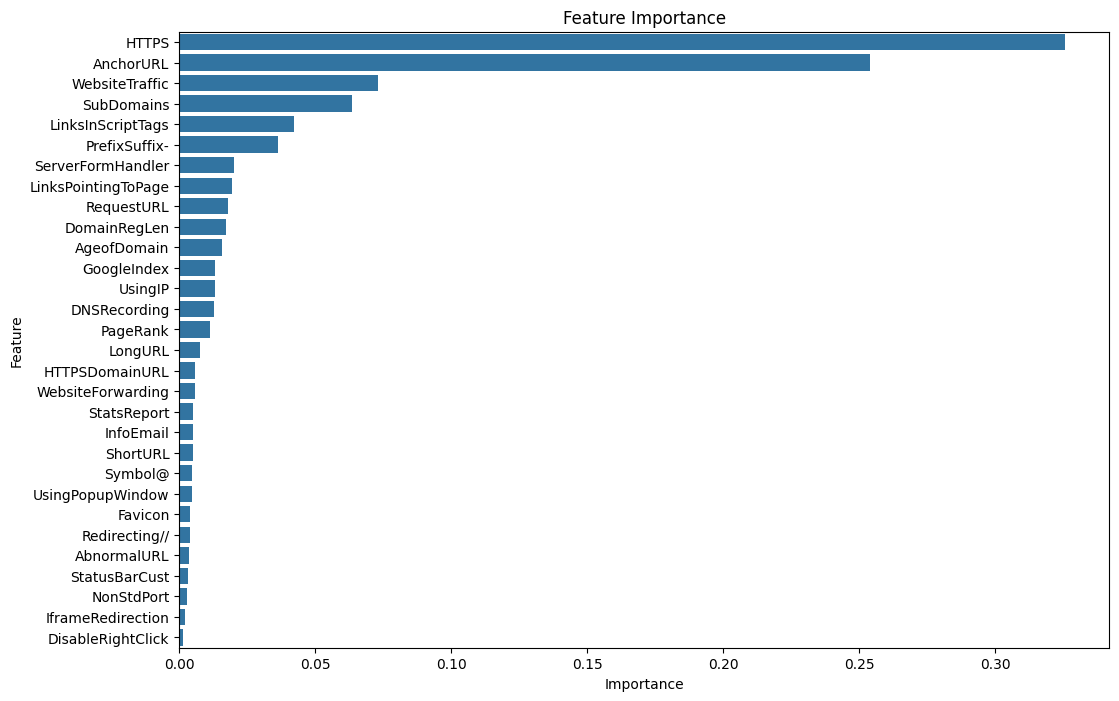

In [24]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]
feature_importances = pd.DataFrame({'Feature': np.array(all_features)[indices], 'Importance': importances[indices]})
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importances)
plt.title('Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

In [25]:
features = selected_features
X = data[features]
y = data[target]

# Split the data into training and testing sets
train_X,test_X,train_Y,test_Y=train_test_split(X,y,test_size=0.3,random_state=2)
combined_data = pd.concat([train_X, test_X])
combined_data.reset_index(drop=True, inplace=True)
display(combined_data)

,UsingIP,LongURL,ShortURL,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,RequestURL,AnchorURL,LinksInScriptTags,ServerFormHandler,AbnormalURL,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,StatsReport
0,1,-1,1,-1,0,-1,1,1,0,-1,-1,1,-1,1,1,-1,1,1
1,1,1,1,-1,-1,1,-1,1,0,0,-1,-1,1,-1,0,-1,1,-1
2,1,-1,1,-1,0,-1,-1,1,-1,0,-1,1,1,1,1,-1,1,1
3,1,-1,1,-1,0,0,-1,1,-1,0,-1,1,1,-1,-1,-1,1,1
4,1,-1,1,-1,-1,1,1,1,1,1,-1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11049,1,-1,1,-1,-1,1,-1,1,0,0,-1,1,1,-1,1,-1,1,-1
11050,1,1,1,-1,0,0,-1,1,-1,0,1,1,1,-1,-1,-1,1,1
11051,1,-1,1,-1,-1,1,-1,1,0,0,-1,1,1,1,1,1,1,1
11052,1,-1,1,1,1,1,-1,1,1,-1,1,1,-1,1,0,1,1,1


In [26]:
X.columns

Index(['UsingIP', 'LongURL', 'ShortURL', 'PrefixSuffix-', 'SubDomains',
       'HTTPS', 'DomainRegLen', 'RequestURL', 'AnchorURL', 'LinksInScriptTags',
       'ServerFormHandler', 'AbnormalURL', 'AgeofDomain', 'DNSRecording',
       'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'StatsReport'],
      dtype='str')

In [27]:
print(train_X.shape)
print(test_X.shape)
print(train_Y.shape)
print(test_Y.shape)

(7737, 18)
(3317, 18)
(7737,)
(3317,)


In [29]:
!pip install python-whois
import re
import ssl
import OpenSSL
import datetime
import requests
import socket
import whois
from bs4 import BeautifulSoup
from urllib.parse import urlparse

def is_ip_address(domain):
    try:
        socket.inet_aton(domain)
        return 1
    except socket.error:
        return -1

def is_long_url(url):
    if len(url) < 54:
        return 1
    elif len(url) <= 75:
        return 0
    else:
        return -1

def is_tiny_url(url):
    tiny_url_pattern = (
        r'bit\.ly|goo\.gl|shorte\.st|go2l\.ink|x\.co|ow\.ly|t\.co|tinyurl|'
        r'tr\.im|is\.gd|cli\.gs|yfrog\.com|migre\.me|ff\.im|tiny\.cc|'
        r'url4\.eu|twit\.ac|su\.pr|twurl\.nl|snipurl\.com|short\.to|'
        r'BudURL\.com|ping\.fm|post\.ly|Just\.as|bkite\.com|snipr\.com|'
        r'fic\.kr|loopt\.us|doiop\.com|short\.ie|kl\.am|wp\.me|rubyurl\.com|'
        r'om\.ly|to\.ly|bit\.do|lnkd\.in|db\.tt|qr\.ae|adf\.ly|bitly\.com|'
        r'cur\.lv|ity\.im|q\.gs|po\.st|bc\.vc|twitthis\.com|u\.to|j\.mp|'
        r'buzurl\.com|cutt\.us|u\.bb|yourls\.org|prettylinkpro\.com|'
        r'scrnch\.me|filoops\.info|vzturl\.com|qr\.net|1url\.com|tweez\.me|'
        r'v\.gd|link\.zip\.net'
    )
    return -1 if re.search(tiny_url_pattern, url) else 1

def has_at_symbol(url):
    return -1 if '@' in url else 1

def has_redirecting_double_slash(url):
    return -1 if url.rfind('//') > 7 else 1

def has_prefix_suffix(domain):
    return -1 if '-' in domain else 1

def count_subdomains(domain):
    subdomain_count = domain.count('.')
    return 1 if subdomain_count == 1 else -1 if subdomain_count == 2 else 0

def get_certificate_info(domain):
    try:
        cert = ssl.get_server_certificate((domain, 443))
        x509 = OpenSSL.crypto.load_certificate(OpenSSL.crypto.FILETYPE_PEM, cert)

        issuer = dict(x509.get_issuer().get_components())
        issuer_name = issuer.get(b'O').decode('utf-8')

        not_before = x509.get_notBefore().decode('utf-8')
        not_after = x509.get_notAfter().decode('utf-8')

        not_before_date = datetime.datetime.strptime(not_before, '%Y%m%d%H%M%SZ')
        not_after_date = datetime.datetime.strptime(not_after, '%Y%m%d%H%M%SZ')
        age = (datetime.datetime.utcnow() - not_before_date).days / 365

        return issuer_name, age, True
    except Exception as e:
        print(f"Error retrieving certificate info: {e}")
        return None, None, False

def is_https(url):
    trusted_issuers = ["GeoTrust", "GoDaddy", "Network Solutions", "Thawte", "Comodo", "Doster", "VeriSign"]
    minimum_age = 1  # years

    if not url.startswith("https://"):
        return -1  # Phishing

    domain = url.split("//")[-1].split("/")[0]
    issuer, age, valid = get_certificate_info(domain)

    if not valid:
        return -1  # Phishing

    if issuer in trusted_issuers:
        if age >= minimum_age:
            return 1  # Legitimate
        else:
            return -1  # Phishing
    else:
        return 0  # Suspicious

def domain_registration_length(domain):
    try:
        whois_info = whois.whois(domain)
        creation_date = whois_info.creation_date
        expiration_date = whois_info.expiration_date
        if isinstance(creation_date, list):
            creation_date = creation_date[0]
        if isinstance(expiration_date, list):
            expiration_date = expiration_date[0]
        age = (expiration_date - creation_date).days / 365
        return 1 if age >= 1 else -1
    except:
        return 0

def has_favicon(url, domain):
    try:
        response = requests.get(url)
        soup = BeautifulSoup(response.text, 'html.parser')
        icon_link = soup.find("link", rel="shortcut icon")
        if icon_link:
            icon_url = urlparse(icon_link['href']).netloc
            return -1 if icon_url and icon_url != domain else 1
    except:
        return 0

def is_non_standard_port(url):
    non_standard_ports = {21, 22, 23,80,443,445, 1433, 1521, 3306, 3389}
    port = urlparse(url).port
    return -1 if port and port in non_standard_ports else 1

def has_https_token(domain):
    return -1 if 'http' in domain else 1

def calculate_request_url(soup, domain):
    try:
        total_links = len(soup.find_all(['img', 'audio', 'embed', 'iframe']))
        external_links = sum(
            1 for tag in soup.find_all(['img', 'audio', 'embed', 'iframe'])
            if urlparse(tag.get('src')).netloc != domain
        )
        if total_links == 0:
            return -1
        percent_external = (external_links / total_links) * 100
        if percent_external < 22:
            return 1
        elif percent_external <= 61:
            return 0
        else:
            return -1
    except:
        return 1

def calculate_url_of_anchor(soup, domain):
    try:
        total_anchors = len(soup.find_all('a'))
        external_anchors = sum(
            1 for a in soup.find_all('a')
            if urlparse(a.get('href')).netloc != domain or a.get('href') in ['#', '']
        )
        if total_anchors == 0:
            return -1
        percent_external = (external_anchors / total_anchors) * 100
        if percent_external < 31:
            return 1
        elif percent_external <= 67:
            return 0
        else:
            return -1
    except:
        return 1

def calculate_meta_script_link(soup, domain):
    try:
        total_tags = len(soup.find_all(['meta', 'script', 'link']))
        external_tags = sum(
            1 for tag in soup.find_all(['meta', 'script', 'link'])
            if urlparse(tag.get('href', '')).netloc != domain
        )
        if total_tags == 0:
            return -1
        percent_external = (external_tags / total_tags) * 100
        if percent_external < 17:
            return 1
        elif percent_external <= 81:
            return 0
        else:
            return -1
    except:
        return 1

def calculate_sfh(soup, domain):
    try:
        forms = soup.find_all('form')
        if any(form.get('action') in ["", "about:blank"] for form in forms):
            return -1
        elif any(urlparse(form.get('action')).netloc != domain for form in forms):
            return 0
        else:
            return 1
    except:
        return 1

def is_submitting_to_email(soup):
    try:
        if any("mailto:" in form.get('action', '') for form in soup.find_all('form')):
            return -1
    except:
        return 1

def extract_hostname_from_whois(url):
    try:
        domain = url.split("//")[-1].split("/")[0]
        whois_info = whois.whois(domain)
        hostname = whois_info.domain_name

        if isinstance(hostname, list):
            hostname = hostname[0]

        return hostname.lower()
    except Exception as e:
        print(f"Error retrieving WHOIS info: {e}")
        return None

def is_abnormal_url(url):
    hostname = extract_hostname_from_whois(url)

    if not hostname:
        return -1  # Phishing, as we couldn't retrieve WHOIS info

    domain_in_url = url.split("//")[-1].split("/")[0].lower()

    if hostname in domain_in_url:
        return 1  # Legitimate
    else:
        return -1  # Phishing

def calculate_website_forwarding(url):
    try:
        response = requests.get(url, allow_redirects=True)
        redirect_count = len(response.history)

        if redirect_count <= 1:
            return 1  # Legitimate
        elif 2 <= redirect_count < 4:
            return 0  # Suspicious
        else:
            return -1  # Phishing
    except Exception as e:
        print(f"Error checking website forwarding: {e}")
        return -1  # Phishing by default if error occurs

def is_status_bar_customized(soup):
    try:
        response = requests.get(url)
        soup = BeautifulSoup(response.content, 'html.parser')

        # Check for onMouseOver events
        scripts = soup.find_all('script')
        for script in scripts:
            if 'onMouseOver' in script.string:
                return -1  # Phishing

        return 1  # Legitimate
    except Exception as e:
        print(f"Error checking status bar customization: {e}")
        return -1  # Phishing by default if error occurs


def is_right_click_disabled(soup):
    try:
        response = requests.get(url)
        soup = BeautifulSoup(response.content, 'html.parser')

        # Check for right-click disabling event
        scripts = soup.find_all('script')
        for script in scripts:
            if 'event.button==2' in script.string:
                return -1  # Phishing

        return 1  # Legitimate
    except Exception as e:
        print(f"Error checking right click disabled: {e}")
        return -1  # Phishing by default if error occurs

def is_using_pop_up_window(soup):
    try:
        response = requests.get(url)
        soup = BeautifulSoup(response.content, 'html.parser')

        scripts = soup.find_all('script')
        for script in scripts:
            if 'window.open' in script.string:
                if '<input' in script.string and 'type="text"' in script.string:
                    return -1  # Phishing

        return 1  # Legitimate
    except Exception as e:
        print(f"Error checking pop-up with text fields: {e}")
        return -1  # Phishing by default if error occurs


def has_iframe_redirection(soup):
    try:
        response = requests.get(url)
        soup = BeautifulSoup(response.content, 'html.parser')

        iframes = soup.find_all('iframe')
        for iframe in iframes:
            if 'frameborder' in iframe.attrs:
                return -1  # Phishing

        return 1  # Legitimate
    except Exception as e:
        print(f"Error checking iframe redirection: {e}")
        return -1  # Phishing by default if error occurs

def calculate_age_of_domain(domain):
    try:
        whois_info = whois.whois(domain)
        age = (whois_info.expiration_date - whois_info.creation_date).days / 30
        return -1 if age >= 6 else 1
    except:
        return 1
#################################
def has_dns_record(domain):
    try:
        whois_info = whois.whois(domain)
        return 1 if whois_info else -1
    except:
        return 1

def calculate_website_traffic(domain):
    try:
        alexa_rank = requests.get(f"http://data.alexa.com/data?cli=10&dat=s&url={domain}").text
        rank = re.search(r'<POPULARITY URL=".*" TEXT="(\d+)" SOURCE="panel">', alexa_rank)
        if rank and int(rank.group(1)) < 100000:
            return 1  # Legitimate
        elif rank and int(rank.group(1)) > 100000:
            return 0  # Suspicious
        else:
            return -1  # Phishing
    except:
        return -1

def calculate_page_rank(domain):
    try:
        pagerank = 0.0  # Example: pagerank = get_pagerank(domain)
        return -1 if pagerank < 0.2 else 1
    except:
        return -1

def is_google_indexed(url):
    try:
        google_search = requests.get(f"https://www.google.com/search?q=site:{url}").text
        return 1 if "did not match any documents" not in google_search else -1
    except:
        return -1

def is_link_pointing_to_page(domain):
    try:
        alexa_rank = requests.get(f"http://data.alexa.com/data?cli=10&dat=s&url={domain}").text
        rank = re.search(r'<LINKSIN NUM="(\d+)"/>', alexa_rank)
        if rank:
            if int(rank.group(1)) == 0:
                return -1  # Phishing
            elif int(rank.group(1)) <= 2:
                return 0  # Suspicious
            else:
                return 1  # Legitimate
        else:
            return -1
    except:
        return -1

def calculate_statistical_report(url):
    report_sites = [
        "phishtank.com", "stopbadware.org", "spamhaus.org",
        "fortiguard.com", "malwaredomainlist.com", "dnswl.org"
    ]
    return -1 if any(site in url for site in report_sites) else 1

def extract_features(url):
    domain = urlparse(url).netloc
    response = requests.get(url)
    soup = BeautifulSoup(response.text, 'html.parser')

    features = {
        'UsingIP': [is_ip_address(domain)],
        'LongURL': [is_long_url(url)],
        'ShortURL': [is_tiny_url(url)],
        'PrefixSuffix-': [has_prefix_suffix(domain)],
        'SubDomains': [count_subdomains(domain)],
        'HTTPS': [is_https(url)],
        'DomainRegLen': [domain_registration_length(domain)],
        'RequestURL': [calculate_request_url(soup, domain)],
        'AnchorURL': [calculate_url_of_anchor(soup, domain)],
        'LinksInScriptTags': [calculate_meta_script_link(soup, domain)],
        'ServerFormHandler': [calculate_sfh(soup, domain)],
        'AbnormalURL': [is_abnormal_url(domain)],
        'AgeofDomain': [calculate_age_of_domain(domain)],
        'DNSRecording': [has_dns_record(domain)],
        'WebsiteTraffic': [calculate_website_traffic(domain)],
        'PageRank': [calculate_page_rank(domain)],
        'GoogleIndex': [is_google_indexed(url)],
        'StatsReport': [calculate_statistical_report(url)]
    }
    for x in features.values():
        if(x[0]==None):
            x[0]=1
    return features

In [30]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,r2_score,confusion_matrix,classification_report
from sklearn.ensemble import VotingClassifier
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_confusion_matrix(test_Y, predict_y):
    C = confusion_matrix(test_Y, predict_y)
    A =(((C.T)/(C.sum(axis=1))).T)
    B =(C/C.sum(axis=0))
    plt.figure(figsize=(20,4))
    labels = [1,2]
    cmap=sns.light_palette("blue")
    plt.subplot(1, 3, 1)
    sns.heatmap(C, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Class')
    plt.ylabel('Original Class')
    plt.title("Confusion matrix")
    plt.subplot(1, 3, 2)
    sns.heatmap(B, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Class')
    plt.ylabel('Original Class')
    plt.title("Precision matrix")
    plt.subplot(1, 3, 3)
    sns.heatmap(A, annot=True, cmap=cmap, fmt=".3f", xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted Class')
    plt.ylabel('Original Class')
    plt.title("Recall matrix")
    plt.show()
def Model(clfs,train_X,train_Y,test_X,test_Y):
    dic = thisdict = {
        "Model": [],
        "TrainAcc": [],
        "TestAcc": []
    }
    predictors = []
    for i in clfs:
        print(i.__class__.__name__)
        model = i.fit(train_X,train_Y)
        predictors.append(model)
        TrainPreds=model.predict(train_X)
        TestPreds=model.predict(test_X)
        TrainAcc = accuracy_score(train_Y,TrainPreds)
        print(f"TrainAcc: {TrainAcc}")
        TestAcc = accuracy_score(test_Y,TestPreds)
        print(f"TestAcc: {TestAcc}")
        print(classification_report(test_Y,TestPreds))
        plot_confusion_matrix(test_Y, TestPreds)
        dic["Model"]
        dic["Model"].append(i.__class__.__name__)
        dic["TrainAcc"].append(TrainAcc)
        dic["TestAcc"].append(TestAcc)
    estimators = []
    for i in predictors:
        estimators.append((i.__class__.__name__,i))
    EnsembleModel = VotingClassifier(estimators=estimators,weights=[3,1,1,2,1])
    print("EnsembleModel")
    model = EnsembleModel.fit(train_X,train_Y)
    predictors.append(model)
    TrainPreds=model.predict(train_X)
    TestPreds=model.predict(test_X)
    TrainAcc = accuracy_score(train_Y,TrainPreds)
    print(f"TrainAcc: {TrainAcc}")
    TestAcc = accuracy_score(test_Y,TestPreds)
    print(f"TestAcc: {TestAcc}")
    print(classification_report(test_Y,TestPreds))
    plot_confusion_matrix(test_Y, TestPreds)
    dic["Model"]
    dic["Model"].append("EnsembleModel")
    dic["TrainAcc"].append(TrainAcc)
    dic["TestAcc"].append(TestAcc)
    return dic, predictors
def MakeInfrence(predictors,url):
    features = extract_features(url)
    test = pd.DataFrame(features)
    prediction = predictors[5].predict(test)
    if prediction==1:
        print(f'>>>>>>>real site=={prediction}')
    else:
        print(f'>>>fake site=={prediction}')



LogisticRegression
TrainAcc: 0.9243892981775882
TestAcc: 0.9192041000904432
              precision    recall  f1-score   support

           0       0.93      0.88      0.91      1458
           1       0.91      0.95      0.93      1859

    accuracy                           0.92      3317
   macro avg       0.92      0.92      0.92      3317
weighted avg       0.92      0.92      0.92      3317



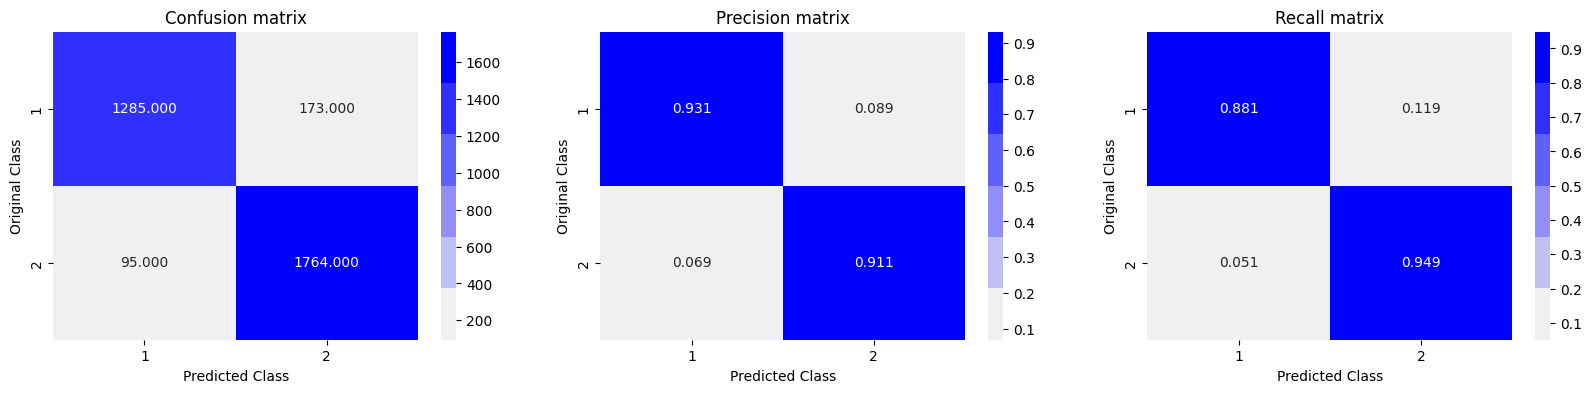

DecisionTreeClassifier
TrainAcc: 0.9838438671319633
TestAcc: 0.9611094362375641
              precision    recall  f1-score   support

           0       0.95      0.96      0.96      1458
           1       0.97      0.96      0.97      1859

    accuracy                           0.96      3317
   macro avg       0.96      0.96      0.96      3317
weighted avg       0.96      0.96      0.96      3317



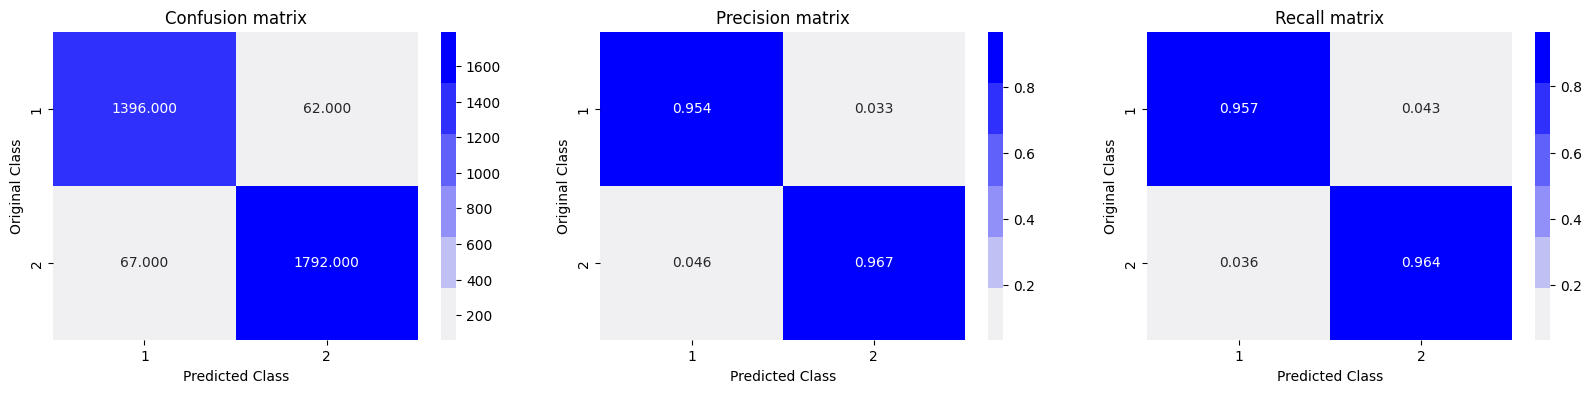

RandomForestClassifier
TrainAcc: 0.9838438671319633
TestAcc: 0.9701537533916189
              precision    recall  f1-score   support

           0       0.97      0.96      0.97      1458
           1       0.97      0.98      0.97      1859

    accuracy                           0.97      3317
   macro avg       0.97      0.97      0.97      3317
weighted avg       0.97      0.97      0.97      3317



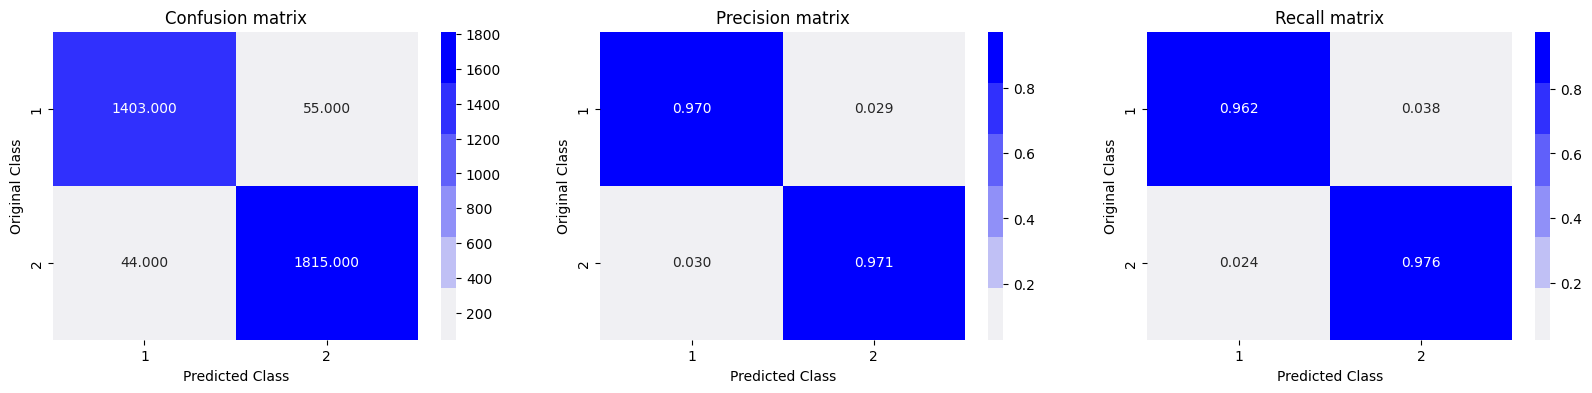

SVC
TrainAcc: 0.9464908879410624
TestAcc: 0.9451311425987338
              precision    recall  f1-score   support

           0       0.96      0.92      0.94      1458
           1       0.94      0.97      0.95      1859

    accuracy                           0.95      3317
   macro avg       0.95      0.94      0.94      3317
weighted avg       0.95      0.95      0.94      3317



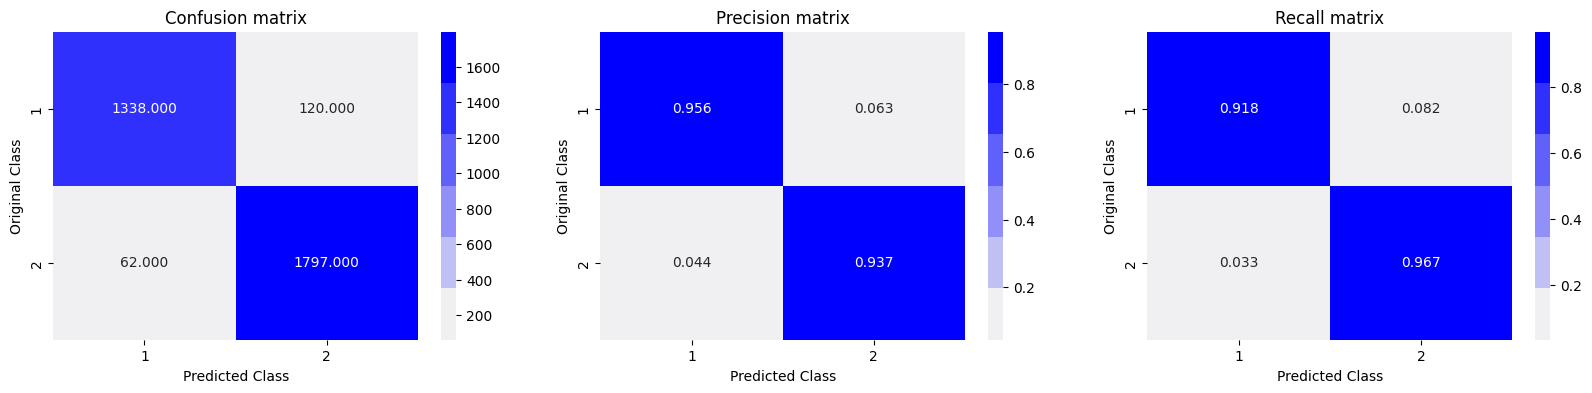

XGBClassifier
TrainAcc: 0.9791909008659687
TestAcc: 0.968947844437745
              precision    recall  f1-score   support

           0       0.97      0.96      0.96      1458
           1       0.97      0.98      0.97      1859

    accuracy                           0.97      3317
   macro avg       0.97      0.97      0.97      3317
weighted avg       0.97      0.97      0.97      3317



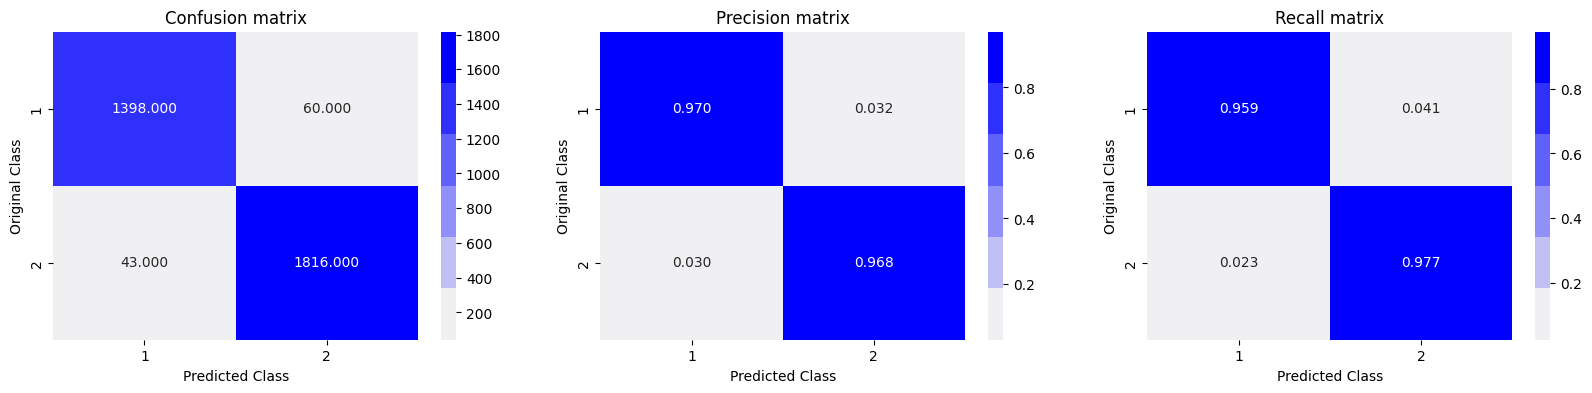

EnsembleModel
TrainAcc: 0.9479126276334496
TestAcc: 0.9448296653602652
              precision    recall  f1-score   support

           0       0.95      0.92      0.94      1458
           1       0.94      0.96      0.95      1859

    accuracy                           0.94      3317
   macro avg       0.95      0.94      0.94      3317
weighted avg       0.95      0.94      0.94      3317



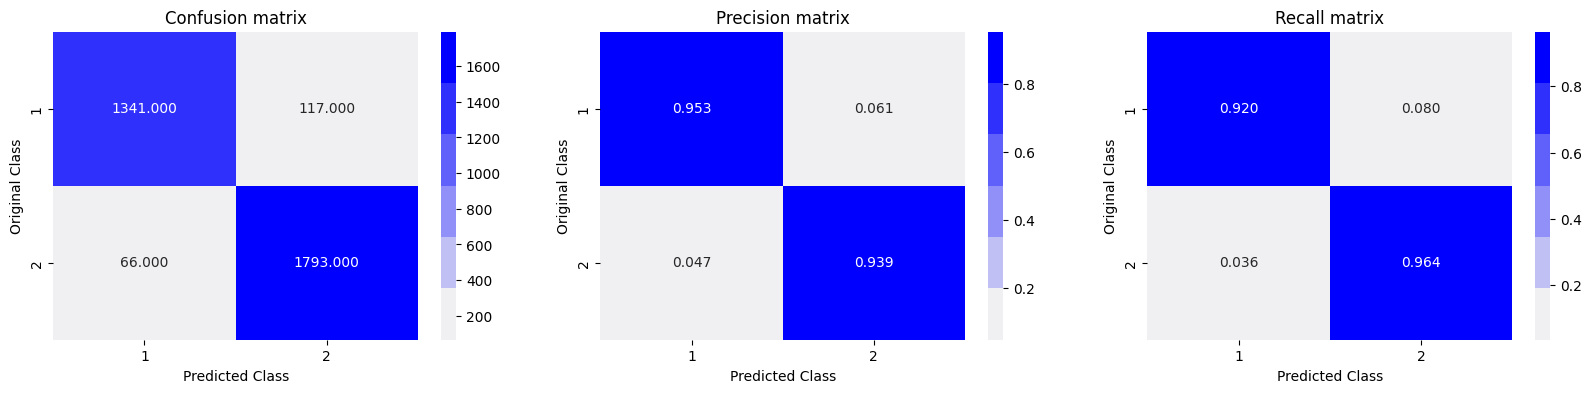

In [31]:
clfs = [LogisticRegression(),DecisionTreeClassifier(),RandomForestClassifier(),SVC(),XGBClassifier()]
dic,predictors = Model(clfs, train_X,train_Y,test_X,test_Y)

In [32]:
ModelResults = pd.DataFrame(dic)

In [33]:
ModelResults.sort_values(ascending=False,by=['TrainAcc',"TestAcc"])

,Model,TrainAcc,TestAcc
2,RandomForestClassifier,0.983844,0.970154
1,DecisionTreeClassifier,0.983844,0.961109
4,XGBClassifier,0.979191,0.968948
5,EnsembleModel,0.947913,0.944830
3,SVC,0.946491,0.945131
0,LogisticRegression,0.924389,0.919204


In [34]:
data.columns

Index(['UsingIP', 'LongURL', 'ShortURL', 'Symbol@', 'Redirecting//',
       'PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'Favicon',
       'NonStdPort', 'HTTPSDomainURL', 'RequestURL', 'AnchorURL',
       'LinksInScriptTags', 'ServerFormHandler', 'InfoEmail', 'AbnormalURL',
       'WebsiteForwarding', 'StatusBarCust', 'DisableRightClick',
       'UsingPopupWindow', 'IframeRedirection', 'AgeofDomain', 'DNSRecording',
       'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'LinksPointingToPage',
       'StatsReport', 'class'],
      dtype='str')

In [35]:
url = "https://google.com" #real 1
MakeInfrence(predictors,url)

/tmp/ipykernel_24880/771939058.py:68: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  age = (datetime.datetime.utcnow() - not_before_date).days / 365


>>>>>>>real site==[1]


In [36]:
url = "https://alienadobe-faa5a.web.app/" #fake 0
MakeInfrence(predictors,url)

/tmp/ipykernel_24880/771939058.py:68: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  age = (datetime.datetime.utcnow() - not_before_date).days / 365
Error trying to connect to socket: closing socket - [Errno -2] Name or service not known
Error trying to connect to socket: closing socket - [Errno -2] Name or service not known
Error trying to connect to socket: closing socket - [Errno -2] Name or service not known
Error trying to connect to socket: closing socket - [Errno -2] Name or service not known


Error retrieving WHOIS info: 'NoneType' object has no attribute 'lower'
>>>fake site==[0]


In [37]:
url = "https://facebook.com" #real 1
MakeInfrence(predictors,url)

/tmp/ipykernel_24880/771939058.py:68: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  age = (datetime.datetime.utcnow() - not_before_date).days / 365


>>>>>>>real site==[1]


In [38]:
!pip install gradio

  Using cached gradio-6.14.0-py3-none-any.whl.metadata (17 kB)
  Using cached audioop_lts-0.2.2-cp313-abi3-manylinux1_x86_64.manylinux_2_28_x86_64.manylinux_2_5_x86_64.whl.metadata (2.0 kB)
  Using cached brotli-1.2.0-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (6.1 kB)
  Using cached fastapi-0.136.1-py3-none-any.whl.metadata (28 kB)
  Using cached gradio_client-2.5.0-py3-none-any.whl.metadata (7.1 kB)
  Using cached groovy-0.1.2-py3-none-any.whl.metadata (6.1 kB)
  Using cached hf_gradio-0.4.1-py3-none-any.whl.metadata (428 bytes)
  Using cached huggingface_hub-1.14.0-py3-none-any.whl.metadata (14 kB)
  Using cached orjson-3.11.9-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (41 kB)
  Using cached pydantic-2.13.4-py3-none-any.whl.metadata (109 kB)
  Using cached pydub-0.25.1-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached python_multipart-0.0.27-py3-none-any.whl.metadata (2.1 kB)
  Using cached pytz-2026.2-py2.py3-none-any.whl.metada

In [39]:
import gradio as gr

# Function to process the URL and make predictions using the trained models
def make_inference_gradio(url):
    features = extract_features(url)  # Extract features from the URL
    test = pd.DataFrame(features)
    prediction = predictors[5].predict(test)  # Using the ensemble model for prediction
    if prediction == 1:
        result = "Legitimate Website"
    else:
        result = "Phishing Website"
    return result

# Define the Gradio interface using the new components
url_input = gr.Textbox(label="Enter Website URL", placeholder="https://example.com")
output_text = gr.Textbox(label="Prediction Result")

# Create the interface
iface = gr.Interface(
    fn=make_inference_gradio,  # Function to use for inference
    inputs=url_input,  # Input component
    outputs=output_text,  # Output component
    title="Phishing Website Detection",
    description="Enter a website URL to check if it is legitimate or phishing.",
)

# Launch the interface
iface.launch()


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


# Robust Evaluation and Error Analysis
- Cross-validated metrics (ROC-AUC, PR-AUC, F1)
- ROC and PR curves plus threshold tuning
- Hold-out test report and error analysis
- Permutation importance for interpretability

In [40]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
 )

SEED = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

models = {
    "LogReg": LogisticRegression(max_iter=1000, solver="liblinear"),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=SEED),
    "SVM": SVC(kernel="rbf", probability=True, random_state=SEED),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=5,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=SEED,
    ),
}

def evaluate_cv(models, X, y, cv):
    rows = []
    probas = {}
    for name, model in models.items():
        if hasattr(model, "predict_proba"):
            y_proba = cross_val_predict(
                model, X, y, cv=cv, method="predict_proba", n_jobs=-1
            )[:, 1]
            y_pred = (y_proba >= 0.5).astype(int)
            probas[name] = y_proba
        else:
            y_pred = cross_val_predict(
                model, X, y, cv=cv, method="predict", n_jobs=-1
            )
            y_proba = None
        rows.append(
            {
                "Model": name,
                "Accuracy": accuracy_score(y, y_pred),
                "Precision": precision_score(y, y_pred, zero_division=0),
                "Recall": recall_score(y, y_pred, zero_division=0),
                "F1": f1_score(y, y_pred, zero_division=0),
                "ROC_AUC": roc_auc_score(y, y_proba) if y_proba is not None else np.nan,
                "PR_AUC": average_precision_score(y, y_proba) if y_proba is not None else np.nan,
            }
        )
    return pd.DataFrame(rows).sort_values(by=["F1", "ROC_AUC"], ascending=False), probas

cv_results, cv_probas = evaluate_cv(models, X, y, cv)
cv_results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
1,RandomForest,0.963633,0.962101,0.973039,0.967539,0.993607,0.993885
3,XGBoost,0.959200,0.959125,0.968004,0.963544,0.994104,0.995237
2,SVM,0.946173,0.943117,0.961345,0.952143,0.986623,0.989499
0,LogReg,0.923919,0.920570,0.944941,0.932596,0.976692,0.980703


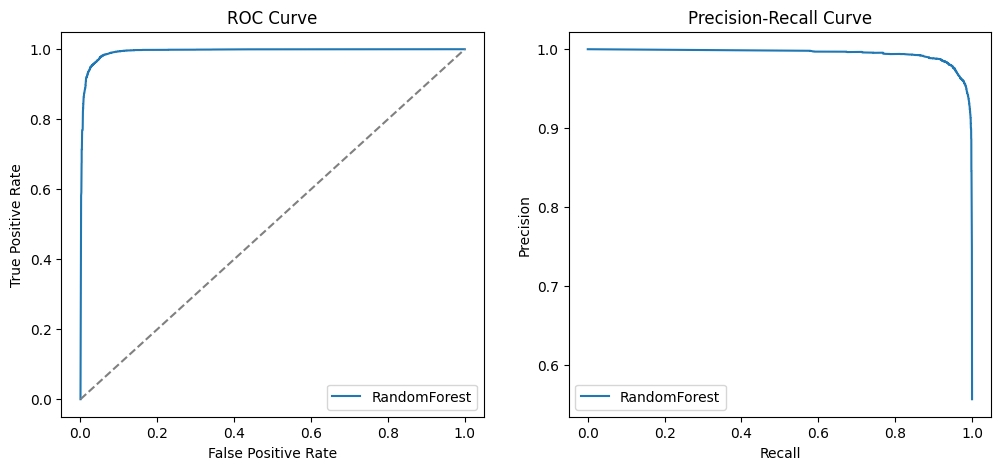

Best threshold (CV): 0.4
Best F1 (CV): 0.9687650168188371


In [41]:
best_name = cv_results.iloc[0]["Model"]
if best_name not in cv_probas:
    best_name = next(iter(cv_probas.keys()))
y_scores = cv_probas[best_name]

fpr, tpr, _ = roc_curve(y, y_scores)
precision, recall, _ = precision_recall_curve(y, y_scores)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, label=f"{best_name}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(recall, precision, label=f"{best_name}")
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

thresholds = np.linspace(0.1, 0.9, 17)
f1s = [f1_score(y, (y_scores >= t).astype(int)) for t in thresholds]
best_t = thresholds[int(np.argmax(f1s))]
print("Best threshold (CV):", best_t)
print("Best F1 (CV):", max(f1s))

Hold-out classification report:
              precision    recall  f1-score   support

           0       0.95      0.92      0.94      1458
           1       0.94      0.96      0.95      1859

    accuracy                           0.94      3317
   macro avg       0.95      0.94      0.94      3317
weighted avg       0.95      0.94      0.94      3317



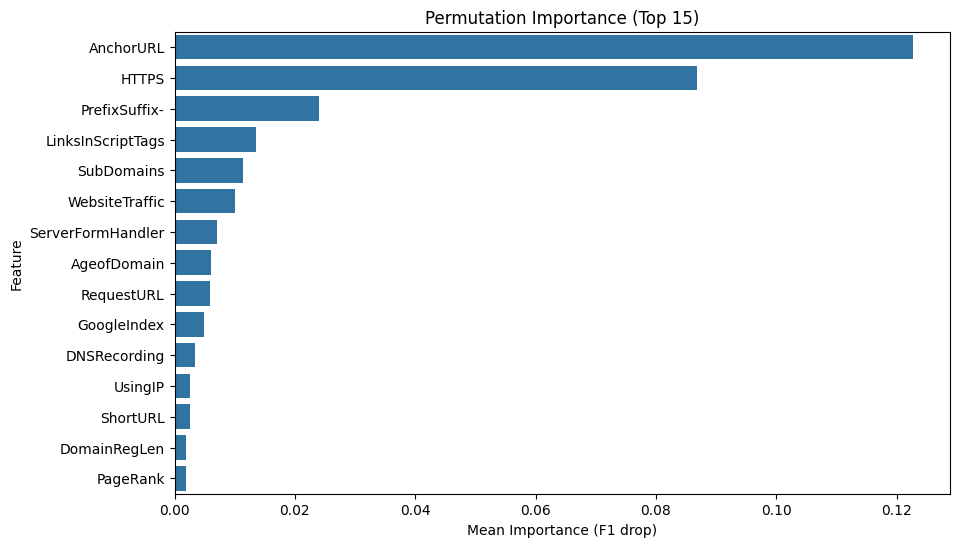

In [42]:
from sklearn.inspection import permutation_importance

ensemble = predictors[5]
test_pred = ensemble.predict(test_X)
print("Hold-out classification report:")
print(classification_report(test_Y, test_pred))

if hasattr(ensemble, "predict_proba"):
    test_scores = ensemble.predict_proba(test_X)[:, 1]
    print("Hold-out ROC-AUC:", roc_auc_score(test_Y, test_scores))
    print("Hold-out PR-AUC:", average_precision_score(test_Y, test_scores))

errors = test_X.copy()
errors["true"] = test_Y.values
errors["pred"] = test_pred
errors["error_type"] = np.where(
    (errors["true"] == 1) & (errors["pred"] == 0),
    "false_negative",
    np.where((errors["true"] == 0) & (errors["pred"] == 1), "false_positive", "correct"),
)
errors["error_type"].value_counts()

errors[errors["error_type"] != "correct"].head(10)

perm = permutation_importance(
    ensemble,
    test_X,
    test_Y,
    n_repeats=10,
    random_state=SEED,
    n_jobs=-1,
    scoring="f1",
)
perm_importances = (
    pd.DataFrame({"Feature": test_X.columns, "Importance": perm.importances_mean})
    .sort_values(by="Importance", ascending=False)
    .reset_index(drop=True)
 )

perm_importances.head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data=perm_importances.head(15))
plt.title("Permutation Importance (Top 15)")
plt.xlabel("Mean Importance (F1 drop)")
plt.ylabel("Feature")
plt.show()